In [2]:
!git clone https://github.com/LUCIUSNJOKU/MONTRA_HOSPITALITY_PJ.git
%cd MONTRA_HOSPITALITY_PJ

Cloning into 'MONTRA_HOSPITALITY_PJ'...
remote: Enumerating objects: 37642, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 37642 (delta 1), reused 15 (delta 1), pack-reused 37624 (from 1)
Receiving objects: 100% (37642/37642), 298.41 MiB | 10.77 MiB/s, done.
Resolving deltas: 100% (5714/5714), done.
/content/MONTRA_HOSPITALITY_PJ


In [3]:
!pip install bertopic sentence-transformers umap-learn hdbscan

In [29]:
import  re
import os
import shutil
import pandas as pd
import numpy as np
from pathlib import Path
from collections import Counter
import torch
from os import mkdir
from os import cpu_count
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt


In [5]:
# Load the Cleaned Dataset
from google.colab import files
uploaded = files.upload()

Saving cleaned_montra_data.csv to cleaned_montra_data.csv


In [6]:
# To create a direstory for the dataset
DATA_DIR = Path("../dataset/processed_data")
DATA_DIR.mkdir(parents =True, exist_ok= True)
print("Directory created:", DATA_DIR.resolve())

# Read the dataset
cleaned_data = pd.read_csv("cleaned_montra_data.csv")
cleaned_data.head()

Directory created: /content/dataset/processed_data


,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,room_type,booking_channel,...,country,previous_stays,hotel_name,location,star_rating,total_rooms,light_text,heavy_text,n_words,label
0,1,1,6699,18,The overall price was fair for what we paid. M...,3.2,2025-06-02,neutral,Suite,Direct Website,...,France,4,The Aberdeen Grand,Aberdeen,4,118,The overall price was fair for what we paid. M...,overall price fair paid consider not,15,positive
1,2,2,11380,23,The room was nothing out of the ordinary for w...,4.0,2025-01-22,positive,Deluxe,Corporate Portal,...,Germany,4,Nottingham Park Hotel,Nottingham,4,95,The room was nothing out of the ordinary for w...,room ordinary paid overall price exceeded expe...,28,positive
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clea...",1.9,2025-03-13,negative,Executive,Travel Agent,...,Ireland,4,The London Boutique,London,4,231,"Unfortunately, the pool was outdated it clear...",unfortunately pool outdated clearly needed upk...,15,negative
3,4,4,982,12,We were disappointed that the neighborhood was...,2.2,2026-03-18,negative,Family Room,Airbnb,...,Nigeria,0,Manchester Metropolitan,Manchester,3,101,We were disappointed that the neighborhood was...,disappointed neighborhood disappointingly way ...,21,positive
4,5,5,615,5,The room service was standard hotel fare for w...,3.3,2025-03-03,neutral,Deluxe,Expedia,...,United States,9,Glasgow Metropolitan,Glasgow,4,214,The room service was standard hotel fare for w...,room service standard hotel fare paid said bed...,39,positive


In [7]:
## Extracting the Review as a Document
doc =(cleaned_data['heavy_text'].astype(str).tolist())
print(f"Total Document:{len(doc)}")
doc[:10]

Total Document:35000


['overall price fair paid consider not',
 'room ordinary paid overall price exceeded expectation great deal quality easily matched price',
 'unfortunately pool outdated clearly needed upkeep wouldn recommend',
 'disappointed neighborhood disappointingly way sadly room turned grimy',
 'room service standard hotel fare paid said bedding decent shape paid cost stay reasonable paid',
 'getting hotel unsafe area really affected stay said check process delayed clear reason really affected stay',
 'couldn asked better base visiting london plus overall restaurant write home expected genuinely impressed arrival experience seamless genuinely great',
 'wonderful time stay nottingham plus surrounding area exceeded expectation ideally situated restaurant shop nearby',
 'house cafe acceptable paid said gym basic but functional paid',
 'manager fine special paid fitness facility special did job surprise']

In [8]:
# Get the city names as a flat list
Uk_cities = cleaned_data["location"].dropna().astype(str).unique().tolist()

# Escape city names and remove empty values
Uk_cities = [re.escape(city.strip()) for city in Uk_cities if city.strip()]

# Create a pattern to match the city names
city_pattern = re.compile(r"\b(" + "|".join(Uk_cities) + r")\b",re.IGNORECASE)

# Remove city names from each document
doc = [city_pattern.sub(" ", text) for text in doc]

# Remove extra spaces
doc = [re.sub(r"\s+", " ", text).strip() for text in doc]

In [9]:
# Normalize the text review
normalized_docs = [duck.lower().strip() for duck in doc]

# Count exact duplicate text
total_docs = len(normalized_docs)
unique_docs = len(set(normalized_docs))
duplicated_docs = total_docs - unique_docs

print(f'Total Document: {total_docs}')
print(f'Unique Document:{unique_docs}')
print(f' Duplicated Dcoument: {duplicated_docs}')

if total_docs > 0:
  duplicated_rate = duplicated_docs/total_docs*100
  print((f' Duplicate_rate: {duplicated_rate:.2f}%'))


Total Document: 35000
Unique Document:34175
 Duplicated Dcoument: 825
 Duplicate_rate: 2.36%


In [10]:
# calculate vocabulary size
all_word = " ".join(normalized_docs).split()
print(f'vocab_size: {len(set(all_word))}')
print(f'vocab_size: {len(all_word)}')

# Display the first 20 common words
print(Counter(all_word).most_common(20))



vocab_size: 387
vocab_size: 439984
[('overall', 12124), ('paid', 11056), ('stay', 11027), ('expected', 9927), ('hotel', 9860), ('time', 8171), ('fine', 8167), ('stood', 5414), ('plus', 5127), ('said', 4912), ('addition', 4898), ('hand', 4663), ('staff', 4580), ('area', 4544), ('but', 4538), ('genuinely', 4436), ('acceptable', 4064), ('arrival', 3903), ('getting', 3739), ('not', 3731)]


In [11]:
# selecting the CPU to apply
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Using device:", device)

Using device: cuda


In [12]:
# create the Embedding model
embedding_model = SentenceTransformer("all-mpnet-base-v2", device=device)
EMB_PATH = DATA_DIR/"review-embeddings.npy"
if EMB_PATH.exists():
  embeddings = np.load(EMB_PATH)
  print('Loaded cached embeddings:', embeddings.shape)
else:
  embeddings = embedding_model.encode(doc, batch_size =64,
                                        show_progress_bar= True)
  np.save(EMB_PATH, embeddings)
  print(f'Embedding Computed and Saved Successfully: {embeddings.shape}')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/547 [00:00<?, ?it/s]

Embedding Computed and Saved Successfully: (35000, 768)


In [13]:
# print the roles
embeddings[:2]

array([[ 0.02140103, -0.00599121,  0.01875282, ...,  0.00217826,
         0.00187598, -0.00563678],
       [-0.00211142, -0.03654831,  0.00749824, ...,  0.00553467,
         0.02303965, -0.0019353 ]], dtype=float32)

In [14]:
# configure the umap to reduce the dimensionality
umap_model = UMAP(n_neighbors= 15, n_components= 5, min_dist = 0.0,
                  metric = "cosine", random_state= 42)

In [15]:
# configure hDBscan
hdbscan_model = HDBSCAN(min_cluster_size= 800, min_samples = 100,
                        metric= 'euclidean', cluster_selection_method= 'eom',
                        prediction_data= True)

In [16]:
# configure countvectorizer
vectorizer_model = CountVectorizer(stop_words = 'english', ngram_range = (1,5), min_df= 5)

In [17]:
# Create the topic model
topic_model = BERTopic(embedding_model= embedding_model, umap_model = umap_model,
                       hdbscan_model= hdbscan_model, vectorizer_model =vectorizer_model,
                       calculate_probabilities = True, verbose = True)
print(topic_model.vectorizer_model)
topics, probabilities = topic_model.fit_transform(doc, embeddings)
print(topic_model.vectorizer_model)

2026-10-26 21:17:49,635 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm


CountVectorizer(min_df=5, ngram_range=(1, 5), stop_words='english')


2026-10-26 21:18:54,218 - BERTopic - Dimensionality - Completed ✓
2026-10-26 21:18:54,222 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-26 21:19:05,085 - BERTopic - Cluster - Completed ✓
2026-10-26 21:19:05,097 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-26 21:19:06,773 - BERTopic - Representation - Completed ✓


CountVectorizer(min_df=5, ngram_range=(1, 5), stop_words='english')


In [18]:
# Reduce the number of topics
topic_model.reduce_topics(doc, nr_topics = 'auto')

2026-10-26 21:19:12,622 - BERTopic - Topic reduction - Reducing number of topics
2026-10-26 21:19:12,639 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-26 21:19:14,294 - BERTopic - Representation - Completed ✓
2026-10-26 21:19:14,299 - BERTopic - Topic reduction - Reduced number of topics from 8 to 8


In [19]:
# Re-assigning the topic outliers(min sample) to a topic(nearest similar topic)
new_topics = topic_model.reduce_outliers(doc,topics,strategy="embeddings")

# Update the topic assignments
topics = new_topics

# Display the updated topic counts
topic_counts = pd.Series(topics).value_counts().sort_index()

display(topic_counts.to_frame(name="Review Count"))


,Review Count
0,11791
1,9548
2,7935
3,1931
4,1652
5,1172
6,971


In [42]:
# inspect the topics to see if any toipc is place by the removed city-mapping
# Create a DataFrame of reviews and their topics
topic_data = pd.DataFrame({"review_text": doc, "topic": topics})

topic_data["topic_id"] = topics

display(topic_model.get_topic_info().head(25))

# List of cities from your city-mapping step
city_names = [city.lower() for city in Uk_cities]

# Find reviews that mention any of these cities
topic_data["mentions_city"] = topic_data["review_text"].str.lower().apply(
    lambda review: any(city in review for city in city_names))

# Display reviews that mention cities, grouped by topic
city_reviews = topic_data[topic_data["mentions_city"]]

display(city_reviews[["topic", "review_text"]].sort_values("topic"))

# Count city-related reviews in each topic
display(city_reviews.groupby("topic").size()
    .reset_index(name="City-related review count")
    .sort_values("City-related review count", ascending=False))


,Topic,Count,Name,CustomName,Representation,Representative_Docs
0,-1,1234,-1_bathroom_bathroom area_expected_clean,Unclassified Reviews,"[bathroom, bathroom area, expected, clean, ove...",[stay fairly ordinary bathroom area fairly tid...
1,0,11136,0_fine_overall_expected_paid,Room Cleanliness,"[fine, overall, expected, paid, hotel, unremar...",[hotel fine unremarkable choice time carpet ac...
2,1,9284,1_genuinely_genuinely impressed_impressed_hone...,Staff and Customer Service,"[genuinely, genuinely impressed, impressed, ho...",[trip got great start business center exceeded...
3,2,7823,2_disappointed_left_stay_really affected,Food and Breakfast,"[disappointed, left, stay, really affected, re...",[wasn experience expected visit said suite neg...
4,3,1897,3_gym_facility_fitness_fitness facility,Location and Accessibility,"[gym, facility, fitness, fitness facility, sta...",[stay fairly ordinary fitness facility adequat...
5,4,1503,4_visit stood_visit stood way_stood way_way,Comfort and Facilities,"[visit stood, visit stood way, stood way, way,...","[visit stood way overall price expected, visit..."
6,5,1165,5_base visiting_couldn asked_better base_base,5_base visiting_couldn asked_better base_base,"[base visiting, couldn asked, better base, bas...",[couldn asked better base visiting genuinely i...
7,6,958,6_hotel_sadly_turned_disappointed,6_hotel_sadly_turned_disappointed,"[hotel, sadly, turned, disappointed, affected,...",[high hope hotel but let rate paid overpriced ...


,topic,review_text


,topic,City-related review count


In [43]:

# Inspect topic keywords
for topic_id in sorted(set(topics)):
    if topic_id == -1:
        continue

    keywords = topic_model.get_topic(topic_id)

    if keywords:
        words = [word for word, score in keywords[:15]]

        # Check whether any city name appears in the keywords
        matching_cities = [city for city in city_names
            if any(city in word.lower() for word in words)]

        if matching_cities:
            print(f"\nTopic {topic_id}")
            print("Matching cities:", matching_cities)
            print("Keywords:", ", ".join(words))


In [44]:
# re-label the topic and do EDA
# re-label Topics

# Get information about the topics
topic_info = topic_model.get_topic_info()

# Display the topic keywords
display(topic_info[["Topic", "Count", "Name"]])

# Create meaningful names for your topics
topic_labels = {
    -1: "Unclassified Reviews",
     0: "Room Cleanliness",
     1: "Staff and Customer Service",
     2: "Food and Breakfast",
     3: "Location and Accessibility",
     4: "Comfort and Facilities"}

# Update topic names in the model
topic_model.set_topic_labels(topic_labels)

# Display the updated topic information
display(topic_model.get_topic_info())


,Topic,Count,Name
0,-1,1234,-1_bathroom_bathroom area_expected_clean
1,0,11136,0_fine_overall_expected_paid
2,1,9284,1_genuinely_genuinely impressed_impressed_hone...
3,2,7823,2_disappointed_left_stay_really affected
4,3,1897,3_gym_facility_fitness_fitness facility
5,4,1503,4_visit stood_visit stood way_stood way_way
6,5,1165,5_base visiting_couldn asked_better base_base
7,6,958,6_hotel_sadly_turned_disappointed


,Topic,Count,Name,CustomName,Representation,Representative_Docs
0,-1,1234,-1_bathroom_bathroom area_expected_clean,Unclassified Reviews,"[bathroom, bathroom area, expected, clean, ove...",[stay fairly ordinary bathroom area fairly tid...
1,0,11136,0_fine_overall_expected_paid,Room Cleanliness,"[fine, overall, expected, paid, hotel, unremar...",[hotel fine unremarkable choice time carpet ac...
2,1,9284,1_genuinely_genuinely impressed_impressed_hone...,Staff and Customer Service,"[genuinely, genuinely impressed, impressed, ho...",[trip got great start business center exceeded...
3,2,7823,2_disappointed_left_stay_really affected,Food and Breakfast,"[disappointed, left, stay, really affected, re...",[wasn experience expected visit said suite neg...
4,3,1897,3_gym_facility_fitness_fitness facility,Location and Accessibility,"[gym, facility, fitness, fitness facility, sta...",[stay fairly ordinary fitness facility adequat...
5,4,1503,4_visit stood_visit stood way_stood way_way,Comfort and Facilities,"[visit stood, visit stood way, stood way, way,...","[visit stood way overall price expected, visit..."
6,5,1165,5_base visiting_couldn asked_better base_base,5_base visiting_couldn asked_better base_base,"[base visiting, couldn asked, better base, bas...",[couldn asked better base visiting genuinely i...
7,6,958,6_hotel_sadly_turned_disappointed,6_hotel_sadly_turned_disappointed,"[hotel, sadly, turned, disappointed, affected,...",[high hope hotel but let rate paid overpriced ...


,topic_id,topic_name,Review Count
0,0,Room Cleanliness,11791
1,1,Staff and Customer Service,9548
2,2,Food and Breakfast,7935
3,3,Location and Accessibility,1931
4,4,Comfort and Facilities,1652
5,5,Other Topics,1172
6,6,Other Topics,971


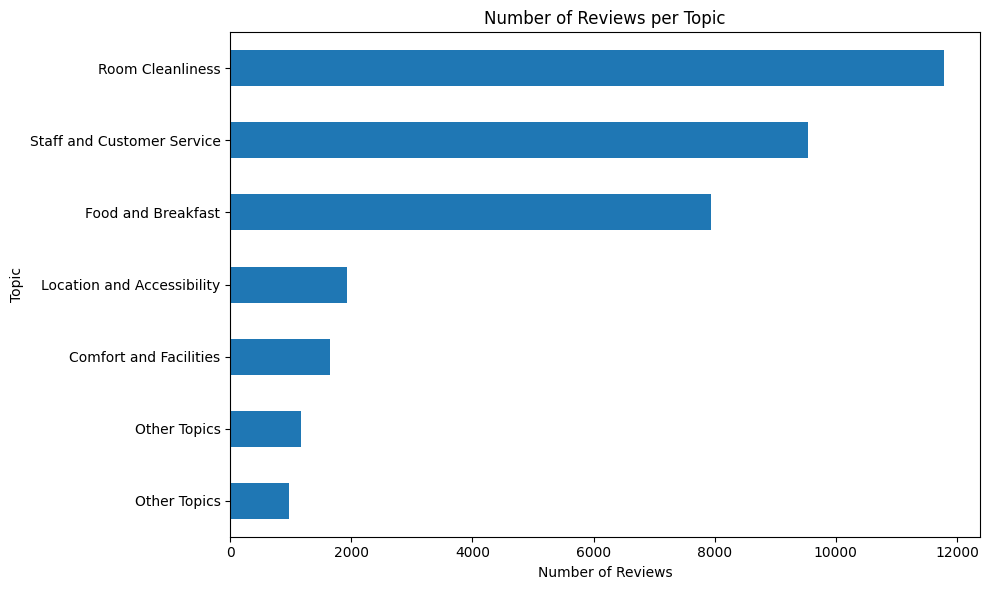

,topic_id,topic_name,Review Count,Percentage (%)
0,0,Room Cleanliness,11791,33.69
1,1,Staff and Customer Service,9548,27.28
2,2,Food and Breakfast,7935,22.67
3,3,Location and Accessibility,1931,5.52
4,4,Comfort and Facilities,1652,4.72
5,5,Other Topics,1172,3.35
6,6,Other Topics,971,2.77



Topic ID: 0 | Topic: Room Cleanliness
- overall price fair paid consider not
- room ordinary paid overall price exceeded expectation great deal quality easily matched price
- room service standard hotel fare paid said bedding decent shape paid cost stay reasonable paid

Topic ID: 2 | Topic: Food and Breakfast
- unfortunately pool outdated clearly needed upkeep wouldn recommend
- disappointed neighborhood disappointingly way sadly room turned grimy
- getting hotel unsafe area really affected stay said check process delayed clear reason really affected stay

Topic ID: 5 | Topic: Other Topics
- couldn asked better base visiting plus overall restaurant write home expected genuinely impressed arrival experience seamless genuinely great
- couldn asked better base visiting plus surrounding area very convenient public transport link right outside overall service team fairly professional expected
- couldn asked better base visiting concierge exceeded expectation incredibly friendly resolved re

In [46]:

# Exploratory Analysis of the Topics

# Create a DataFrame of topic assignments
topic_data = pd.DataFrame({"review_text": doc, "topic_id": topics})

# Add readable topic names
topic_data["topic_name"] = (topic_data["topic_id"]
    .map(topic_labels).fillna("Other Topics"))

# Number of reviews per topic
topic_counts = (topic_data.groupby(["topic_id", "topic_name"]).size()
    .reset_index(name="Review Count")
    .sort_values("Review Count", ascending=False))

display(topic_counts)

# Plot review counts by topic (topic names only)
topic_counts.sort_values("Review Count").plot(x="topic_name",
    y="Review Count", kind="barh", figsize=(10, 6),
    title="Number of Reviews per Topic", xlabel="Number of Reviews",
    ylabel="Topic", legend=False)

plt.tight_layout()
plt.show()

# Calculate topic percentages
topic_percentages = (topic_data.groupby(["topic_id", "topic_name"])
    .size().reset_index(name="Review Count"))

topic_percentages["Percentage (%)"] = (topic_percentages["Review Count"]
    / len(topic_data) * 100).round(2)

display(topic_percentages)

# Display sample reviews for each topic
for topic_id, topic_name in (topic_data[["topic_id", "topic_name"]].drop_duplicates()
    .itertuples(index=False, name=None)):
    print(f"\nTopic ID: {topic_id} | Topic: {topic_name}")

    samples = topic_data.loc[topic_data["topic_id"] == topic_id, "review_text"].head(3)

    for review in samples:
        print("-", review)


,Review Count
topic_name,
Room Cleanliness,11791
Staff and Customer Service,9548
Food and Breakfast,7935
Other Topics,2143
Location and Accessibility,1931
Comfort and Facilities,1652


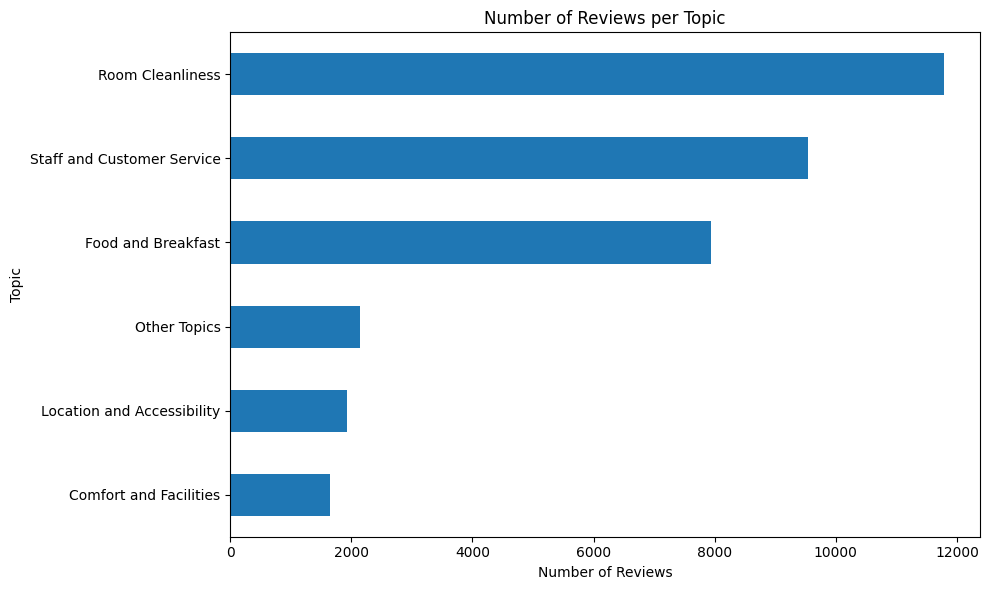

,Percentage (%)
topic_name,
Room Cleanliness,33.69
Staff and Customer Service,27.28
Food and Breakfast,22.67
Other Topics,6.12
Location and Accessibility,5.52
Comfort and Facilities,4.72



Topic: Room Cleanliness
- overall price fair paid consider not
- room ordinary paid overall price exceeded expectation great deal quality easily matched price
- room service standard hotel fare paid said bedding decent shape paid cost stay reasonable paid

Topic: Food and Breakfast
- unfortunately pool outdated clearly needed upkeep wouldn recommend
- disappointed neighborhood disappointingly way sadly room turned grimy
- getting hotel unsafe area really affected stay said check process delayed clear reason really affected stay

Topic: Other Topics
- couldn asked better base visiting plus overall restaurant write home expected genuinely impressed arrival experience seamless genuinely great
- couldn asked better base visiting plus surrounding area very convenient public transport link right outside overall service team fairly professional expected
- couldn asked better base visiting concierge exceeded expectation incredibly friendly resolved request minute genuinely great

Topic: Staff

In [23]:
# Exploratory Analysis of the Topics
# Create a DataFrame of topic assignments
topic_data = pd.DataFrame({"review_text": doc, "topic": topics})

# Add readable topic names
topic_data["topic_name"] = topic_data["topic"].map(topic_labels).fillna("Other Topics")

# 1. Number of reviews per topic
topic_counts = topic_data["topic_name"].value_counts()

display(topic_counts.to_frame("Review Count"))

# 2. Plot review counts by topic
topic_counts.sort_values().plot(kind="barh",figsize=(10, 6),
    title="Number of Reviews per Topic",xlabel="Number of Reviews",
    ylabel="Topic")

plt.tight_layout()
plt.show()

# 3. Calculate topic percentages
topic_percentages = (topic_data["topic_name"].value_counts(normalize=True).mul(100).round(2))

display(topic_percentages.to_frame("Percentage (%)"))

# 4. Display sample reviews for each topic
for topic_name in topic_data["topic_name"].unique():
    print(f"\nTopic: {topic_name}")

    samples = topic_data.loc[topic_data["topic_name"] == topic_name, "review_text"].head(3)

    for review in samples:
        print("-", review)


In [47]:
# Exploring the most importance words in the topic

# Display the top 10 keywords for each topic
for topic_id in topic_model.get_topic_info()["Topic"]:
    if topic_id == -1:
        continue

    print(f"\nTopic {topic_id}:")

    keywords = topic_model.get_topic(topic_id)

    if keywords:
        print(", ".join(word for word, score in keywords[:10]))



Topic 0:
fine, overall, expected, paid, hotel, unremarkable, acceptable, fairly, hotel fine, ordinary

Topic 1:
genuinely, genuinely impressed, impressed, honestly, exceeded expectation, exceeded, expectation, time, great, stood

Topic 2:
disappointed, left, stay, really affected, really, really affected stay, affected stay, affected, turned, sadly

Topic 3:
gym, facility, fitness, fitness facility, stay, overall, paid, expected, fine, functional

Topic 4:
visit stood, visit stood way, stood way, way, visit, stood, overall, expected visit stood way, expected visit stood, expected

Topic 5:
base visiting, couldn asked, better base, base, asked better base visiting, asked better, asked better base, visiting, couldn, couldn asked better

Topic 6:
hotel, sadly, turned, disappointed, affected, really affected stay, really, really affected, affected stay, unfortunately


In [49]:
# Create folders
RESULTS_DIR = Path("../Results")
MODEL_DIR = Path("../Model")
DATASET_DIR= Path("../dataset")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the BERTopic model
topic_model.save(
    str(MODEL_DIR / "hotel_review_topic_model"),
    serialization="safetensors",
    save_ctfidf=True,
    save_embedding_model="sentence-transformers/all-mpnet-base-v2")

# Save topic information as CSV
topic_model.get_topic_info().to_csv(
    RESULTS_DIR / "reports_topic_info.csv",
    index=False)
topic_data.to_csv("../dataset/processed_data/reviews_with_topics.csv", index=False)

print("BERTopic model and CSV saved successfully!")

BERTopic model and CSV saved successfully!


In [50]:
# download the saved Folders

# Compress the Model folder into a ZIP file
shutil.make_archive("/content/Model", "zip", "../Model")

# Compress the Results folder into a ZIP file
shutil.make_archive("/content/Results", "zip", "../Results")

# Compress the Dataset folder into a ZIP file
shutil.make_archive("/content/dataset", "zip", "../dataset")

print("Model folder compressed successfully!")
print("Results folder compressed successfully!")
print("Dataset folder compressed successfully!")

Model folder compressed successfully!
Results folder compressed successfully!
Dataset folder compressed successfully!


In [51]:
from google.colab import files

files.download("/content/Model.zip")
files.download("/content/Results.zip")
files.download("/content/dataset.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>